In [1]:
import scanpy as sc
import anndata
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize']=(8,8) #rescale figures


In [2]:
from adjustText import adjust_text

def gen_mpl_labels(
    adata, groupby, exclude=(), ax=None, adjust_kwargs=None, text_kwargs=None
):
    if adjust_kwargs is None:
        adjust_kwargs = {"text_from_points": False}
    if text_kwargs is None:
        text_kwargs = {}

    medians = {}

    for g, g_idx in adata.obs.groupby(groupby).groups.items():
        if g in exclude:
            continue
        medians[g] = np.median(adata[g_idx].obsm["X_umap"], axis=0)

    if ax is None:
        texts = [
            plt.text(x=x, y=y, s=k, **text_kwargs) for k, (x, y) in medians.items()
        ]
    else:
        texts = [ax.text(x=x, y=y, s=k, **text_kwargs) for k, (x, y) in medians.items()]

    adjust_text(texts, **adjust_kwargs)


In [3]:
#Import color palette to get consistent colors across figures
import pickle  
with open('/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/colordict.pkl', 'rb') as f:
        colordict = pickle.load(f)

# Reference atlas

In [5]:
source_adata =sc.read("/storage/groups/ml01/workspace/jan.domke/Data/atlas_data.h5ad")

In [6]:
sc.pp.neighbors(source_adata, use_rep="X_scANVI", n_neighbors=30)
sc.tl.umap(source_adata)

2022-02-16 10:12:58.230925: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /opt/R/lib/R/lib
2022-02-16 10:12:58.230956: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


In [7]:
source_adata_plot = sc.pp.subsample(source_adata, fraction=1., copy=True)

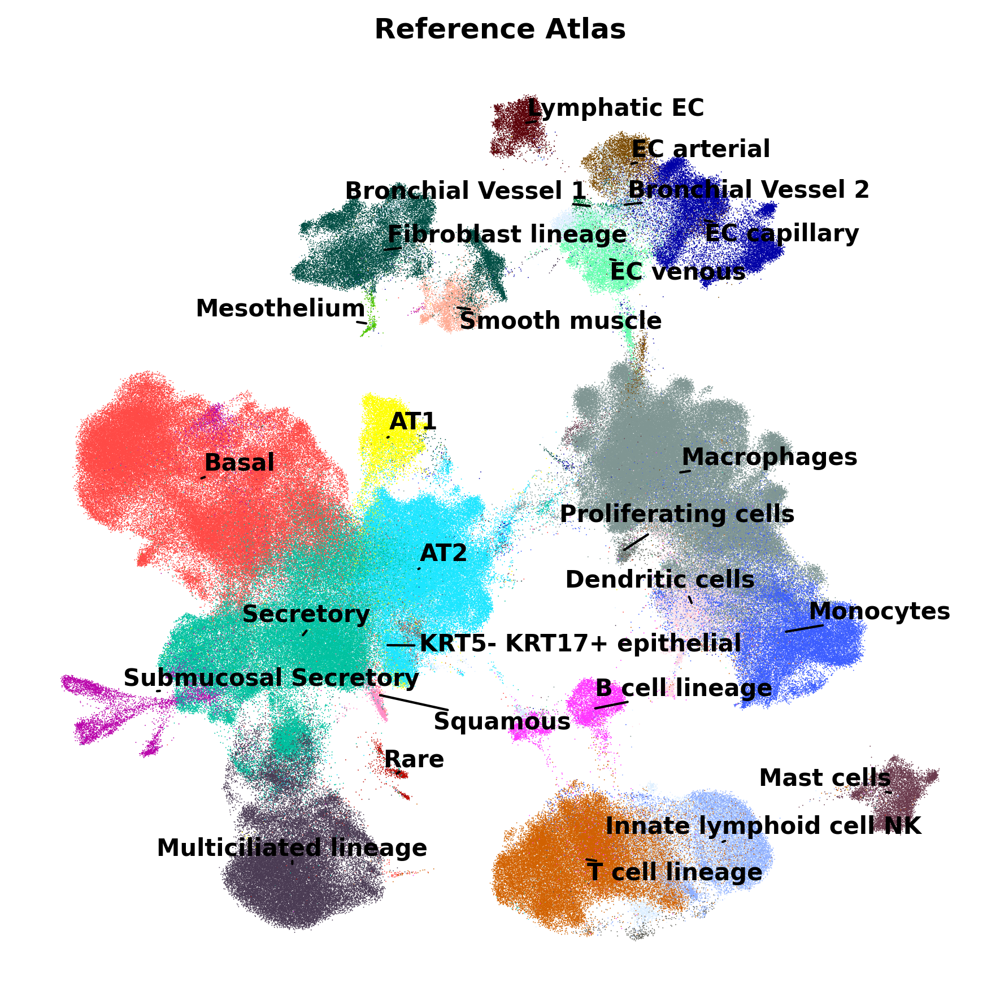

In [115]:
with plt.rc_context({"figure.figsize": (6,6), "figure.dpi": 300, "figure.frameon": False}):
    ax = sc.pl.umap(source_adata_plot, color="scanvi_label", palette = colordict, size = 0.75, sort_order = False, show=False, legend_loc=None, frameon=False)
    gen_mpl_labels(
        source_adata_plot,
        "scanvi_label",
        exclude=("None","Megakaryocytes","unlabeled","Neutrophilic","Proliferating cells"),  # This was before we had the `nan` behaviour
        ax=ax,
        adjust_kwargs=dict(arrowprops=dict(arrowstyle='-', color='black')),
        text_kwargs=dict(fontsize=10, weight="semibold"),
    )
    ax.annotate('Proliferating cells', (0.61, 0.44), #arrow starts here
            xytext=(0.55, 0.47), xycoords='figure fraction',
                arrowprops=dict(arrowstyle='-', color='black'),
                fontsize=10, weight="semibold")
    fig = ax.get_figure()
    fig.tight_layout()
    plt.title("Reference Atlas",fontweight="bold")
    plt.savefig("figures/Reference_atlas_bold.png")
    #plt.show()

/opt/python/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:1227: FutureWarning: Categorical.replace is deprecated and will be removed in a future version. Use Series.replace directly instead.
  values = values.replace(values.categories.difference(groups), np.nan)


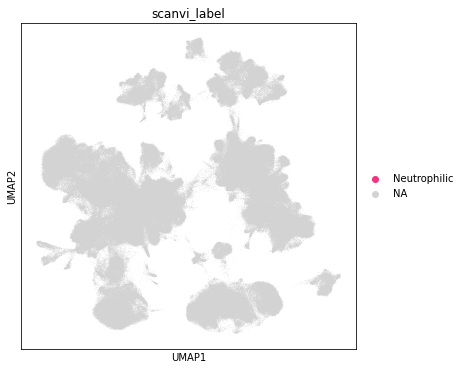

In [109]:
check = sc.pl.umap(source_adata_plot, color="scanvi_label", palette = colordict, size = 0.75, sort_order = False, groups="Neutrophilic")

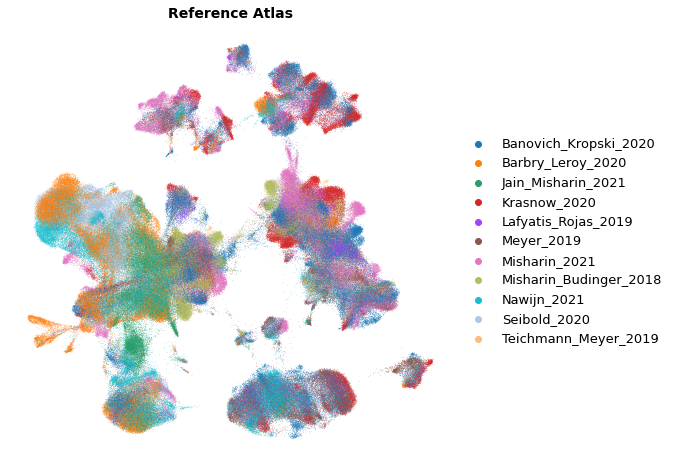

In [21]:
ax = sc.pl.umap(source_adata_plot, color="study", size = 1, sort_order = False, show=False, frameon=False, legend_fontsize = 13, legend_fontweight="semibold" )
fig = ax.get_figure()
#fig.tight_layout()
plt.title("Reference Atlas",fontweight="bold",size=14)
plt.savefig("figures/Reference_atlas_study.png",dpi=300, bbox_inches='tight')
#plt.show()

# Healthy Extension

In [22]:
# Import healthy models
denovo_recalc_healthy = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Healthy/healthy_denovo_recalc_milo.h5ad")
denovo_ref_healthy = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Healthy/healthy_denovo_ref_milo.h5ad")
scarches_unlabeled_healthy = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Healthy/healthy_scarches_unlabeled_milo.h5ad")
scarches_labeled_healthy = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Healthy/healthy_scarches_labeled_milo.h5ad")

In [23]:
# get original scanvi_labels for scarches_unlabeld back
scarches_unlabeled_healthy.obs["scanvi_label_original"] = scarches_unlabeled_healthy.obs["scanvi_label_original"].astype("string")
scarches_unlabeled_healthy.obs.loc[scarches_unlabeled_healthy.obs.origin=="reference","scanvi_label_original"] = scarches_unlabeled_healthy.obs.loc[scarches_unlabeled_healthy.obs.origin=="reference","scanvi_label"].astype(str)
scarches_unlabeled_healthy.obs["scanvi_label_original"] = scarches_unlabeled_healthy.obs["scanvi_label_original"].astype("category")

In [137]:
denovo_recalc_healthy_plot = sc.pp.subsample(denovo_recalc_healthy, fraction=1., copy=True)
denovo_ref_healthy_plot = sc.pp.subsample(denovo_ref_healthy, fraction=1., copy=True)
scarches_unlabeled_healthy_plot = sc.pp.subsample(scarches_unlabeled_healthy, fraction=1., copy=True)
scarches_labeled_healthy_plot = sc.pp.subsample(scarches_labeled_healthy, fraction=1., copy=True)

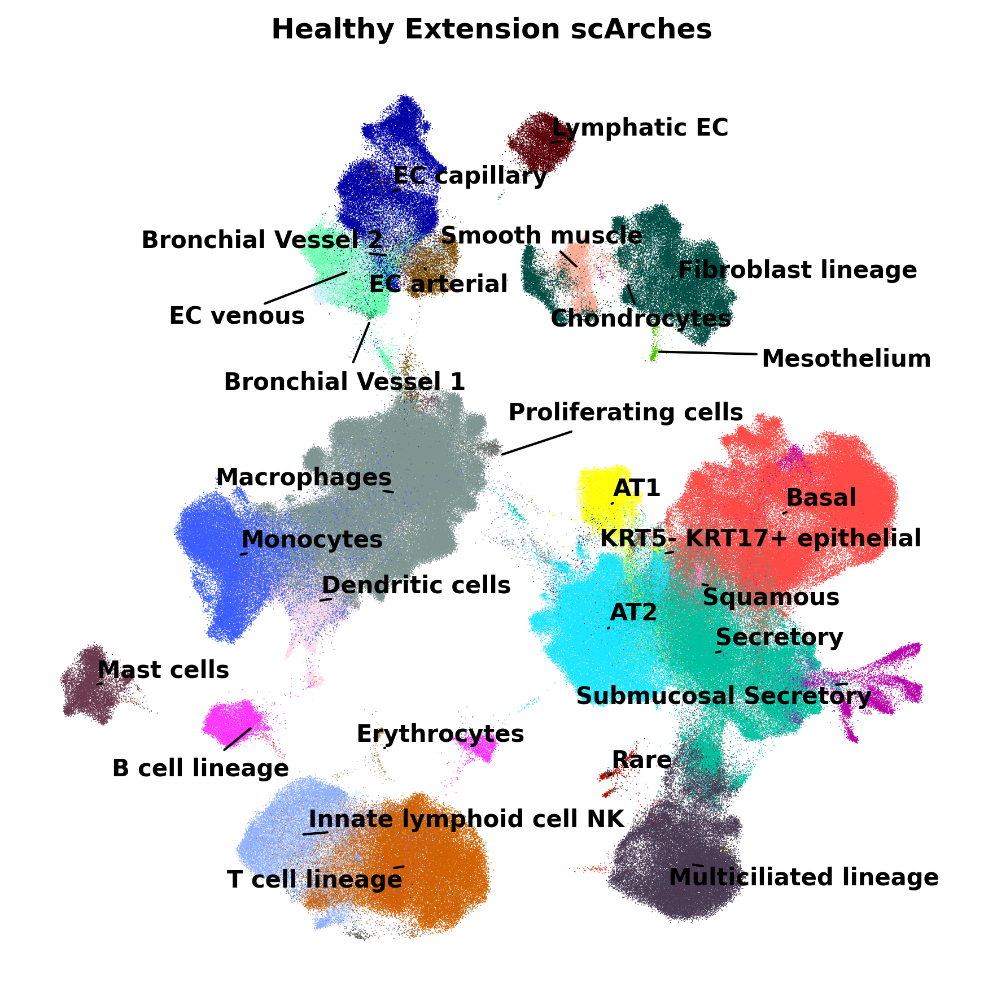

In [147]:
with plt.rc_context({"figure.figsize": (6,6), "figure.dpi": 300, "figure.frameon": False}):
    ax = sc.pl.umap(scarches_unlabeled_healthy_plot, color="scanvi_label_original", palette = colordict, size = 0.75, sort_order = False, show=False, legend_loc=None, frameon=False)
    gen_mpl_labels(
        scarches_unlabeled_healthy_plot,
        "scanvi_label_original",
        exclude=("None","Megakaryocytes","unlabeled","Neutrophilic","Proliferating cells", "Schwann cells", "Bronchial Vessel 1", "B cell lineage"),  
        ax=ax,
        adjust_kwargs=dict(arrowprops=dict(arrowstyle='-', color='black')),
        text_kwargs=dict(fontsize=10, weight="semibold"),
    )
    ax.annotate('Proliferating cells', (0.49, 0.535), #arrow starts here
            xytext=(0.5, 0.57), xycoords='figure fraction',
                arrowprops=dict(arrowstyle='-', color='black'),
                fontsize=10, weight="semibold")
    ax.annotate('Bronchial Vessel 1', (0.365, 0.67), #arrow starts here
            xytext=(0.22, 0.6), xycoords='figure fraction',
                arrowprops=dict(arrowstyle='-', color='black'),
                fontsize=10, weight="semibold")
    ax.annotate('B cell lineage', (0.25, 0.27), #arrow starts here
            xytext=(0.11, 0.22), xycoords='figure fraction',
                arrowprops=dict(arrowstyle='-', color='black'),
                fontsize=10, weight="semibold")
    fig = ax.get_figure()
    fig.tight_layout()
    plt.title("Healthy Extension scArches",fontweight="bold")
    plt.savefig("figures/Healthy_extension_scArches.png")
    #plt.show()
   

/opt/python/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:1227: FutureWarning: Categorical.replace is deprecated and will be removed in a future version. Use Series.replace directly instead.
  values = values.replace(values.categories.difference(groups), np.nan)


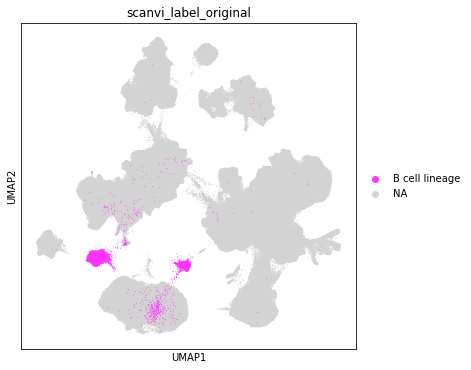

In [142]:
sc.pl.umap(scarches_unlabeled_healthy_plot, color=["scanvi_label_original"], palette = colordict, size = 3,groups=["B cell lineage"])

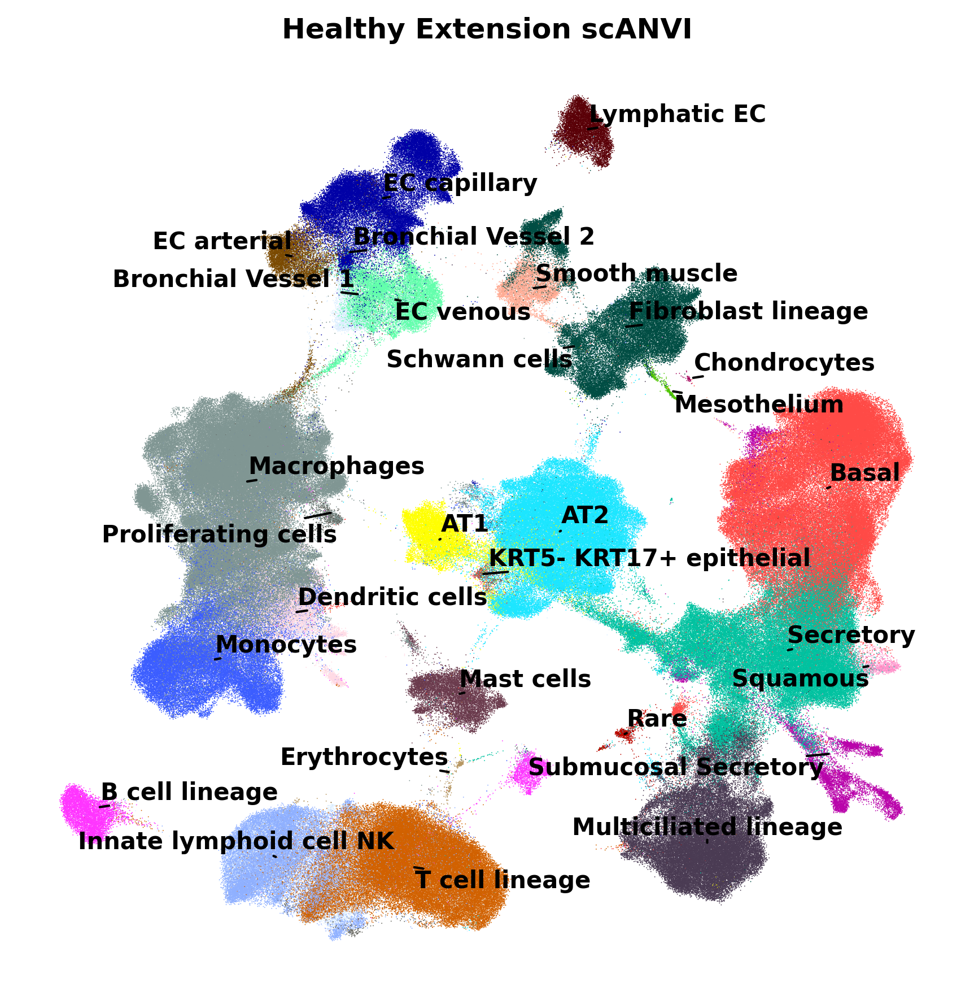

In [121]:
with plt.rc_context({"figure.figsize": (6,6), "figure.dpi": 300, "figure.frameon": False}):
    ax = sc.pl.umap(denovo_recalc_healthy_plot, color="scanvi_label", palette = colordict, size = 0.75, sort_order = False, show=False, legend_loc=None, frameon=False)
    gen_mpl_labels(
        denovo_recalc_healthy_plot,
        "scanvi_label",
        exclude=("None","Megakaryocytes","unlabeled","Neutrophilic","Proliferating cells"),  # This was before we had the `nan` behaviour
        ax=ax,
        adjust_kwargs=dict(arrowprops=dict(arrowstyle='-', color='black')),
        text_kwargs=dict(fontsize=10, weight="semibold"),
    )

    ax.annotate('Proliferating cells', (0.33, 0.48), #arrow starts here
            xytext=(0.1, 0.45), xycoords='figure fraction',
                arrowprops=dict(arrowstyle='-', color='black'),
                fontsize=10, weight="semibold")
    fig = ax.get_figure()
    fig.tight_layout()
    plt.title("Healthy Extension scANVI",fontweight="bold")
    plt.savefig("figures/Healthy_extension_scANVI.png")
    #plt.show()
   

/opt/python/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:1227: FutureWarning: Categorical.replace is deprecated and will be removed in a future version. Use Series.replace directly instead.
  values = values.replace(values.categories.difference(groups), np.nan)


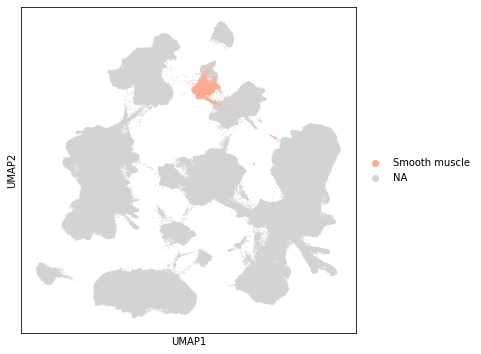

In [102]:
sc.pl.umap(denovo_recalc_healthy_plot, color=["scanvi_label"], palette = colordict, size = 3,groups="Smooth muscle"    )

# IPF Extension

In [46]:
# Import ipf models
denovo_recalc_ipf = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/IPF/ipf_denovo_recalc_milo.h5ad")
denovo_ref_ipf = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/IPF/ipf_denovo_ref_milo.h5ad")
scarches_unlabeled_ipf = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/IPF/ipf_scarches_unlabeled_milo.h5ad")
scarches_labeled_ipf = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/IPF/ipf_scarches_labeled_milo.h5ad")

In [47]:
# get original scanvi_labels for scarches_unlabeld back
scarches_unlabeled_ipf.obs["scanvi_label_original"] = scarches_unlabeled_ipf.obs["scanvi_label_original"].astype("string")
scarches_unlabeled_ipf.obs.loc[scarches_unlabeled_ipf.obs.origin=="reference","scanvi_label_original"] = scarches_unlabeled_ipf.obs.loc[scarches_unlabeled_ipf.obs.origin=="reference","scanvi_label"].astype(str)
scarches_unlabeled_ipf.obs["scanvi_label_original"] = scarches_unlabeled_ipf.obs["scanvi_label_original"].astype("category")

In [48]:
denovo_recalc_ipf_plot = sc.pp.subsample(denovo_recalc_ipf, fraction=1., copy=True)
denovo_ref_ipf_plot = sc.pp.subsample(denovo_ref_ipf, fraction=1., copy=True)
scarches_unlabeled_ipf_plot = sc.pp.subsample(scarches_unlabeled_ipf, fraction=1., copy=True)
scarches_labeled_ipf_plot = sc.pp.subsample(scarches_labeled_ipf, fraction=1., copy=True)

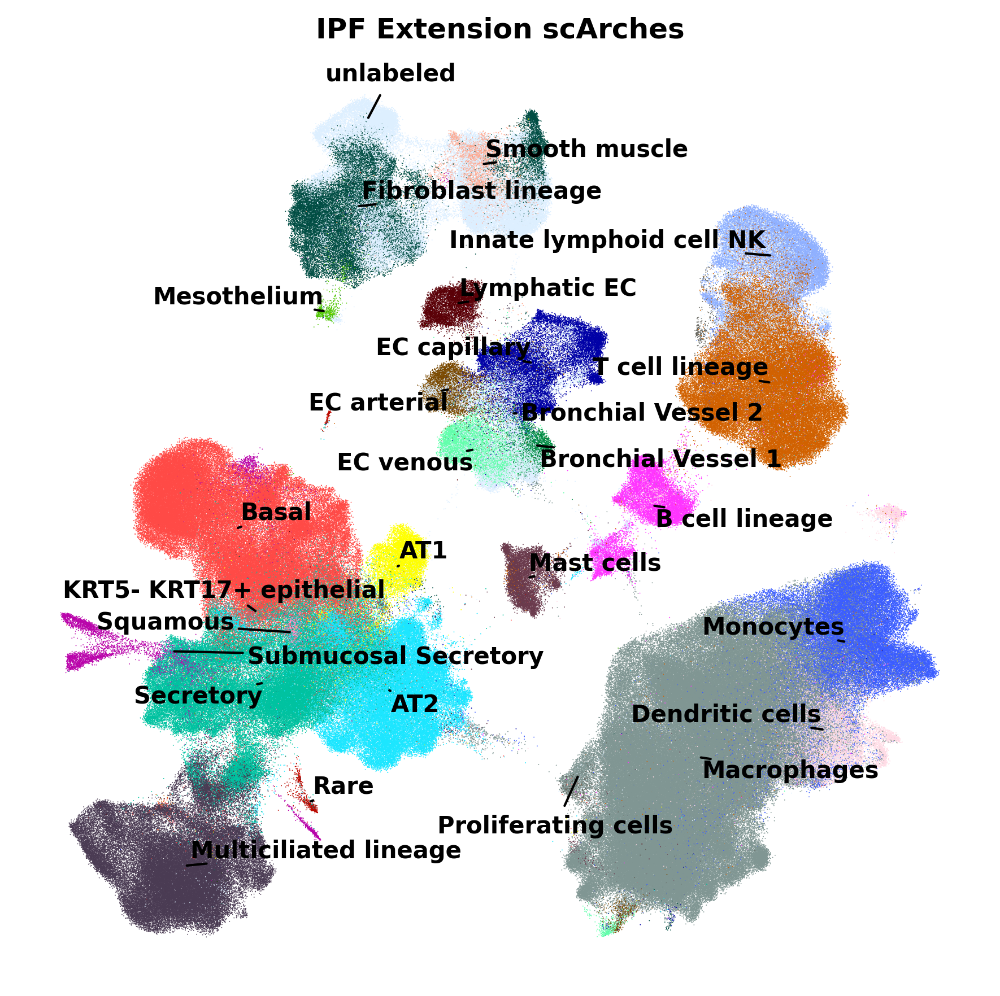

In [71]:
with plt.rc_context({"figure.figsize": (6,6), "figure.dpi": 300, "figure.frameon": False}):
    ax = sc.pl.umap(scarches_unlabeled_ipf_plot, color="scanvi_label_original", palette = colordict, size = 0.75, sort_order = False, show=False, legend_loc=None, frameon=False)
    gen_mpl_labels(
        scarches_unlabeled_ipf_plot,
        "scanvi_label_original",
        exclude=("None","unlabeled","Neutrophilic","Megakaryocytes","Proliferating cells","Erythroblast"),  
        ax=ax,
        adjust_kwargs=dict(arrowprops=dict(arrowstyle='-', color='black')),
        text_kwargs=dict(fontsize=10, weight="semibold"),
    )
    ax.annotate('unlabeled', (0.36, 0.86), #arrow starts here
            xytext=(0.32, 0.9), xycoords='figure fraction',
                arrowprops=dict(arrowstyle='-', color='black'),
                fontsize=10, weight="semibold")
    ax.annotate('Proliferating cells', (0.57, 0.22), #arrow starts here
            xytext=(0.43, 0.16), xycoords='figure fraction',
                arrowprops=dict(arrowstyle='-', color='black'),
                fontsize=10, weight="semibold")
    fig = ax.get_figure()
    fig.tight_layout()
    plt.title("IPF Extension scArches",fontweight="bold")
    plt.savefig("figures/IPF_extension_scArches.png")
    #plt.show()
   

/opt/python/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:1227: FutureWarning: Categorical.replace is deprecated and will be removed in a future version. Use Series.replace directly instead.
  values = values.replace(values.categories.difference(groups), np.nan)


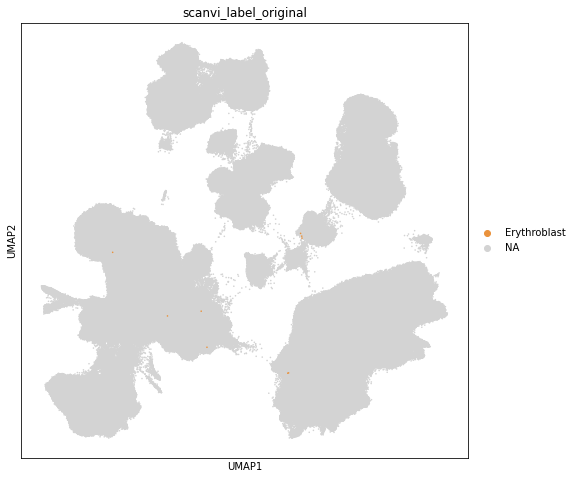

In [69]:
sc.pl.umap(scarches_unlabeled_ipf_plot, color=["scanvi_label_original"], palette = colordict, size = 10,groups=["Erythroblast"])

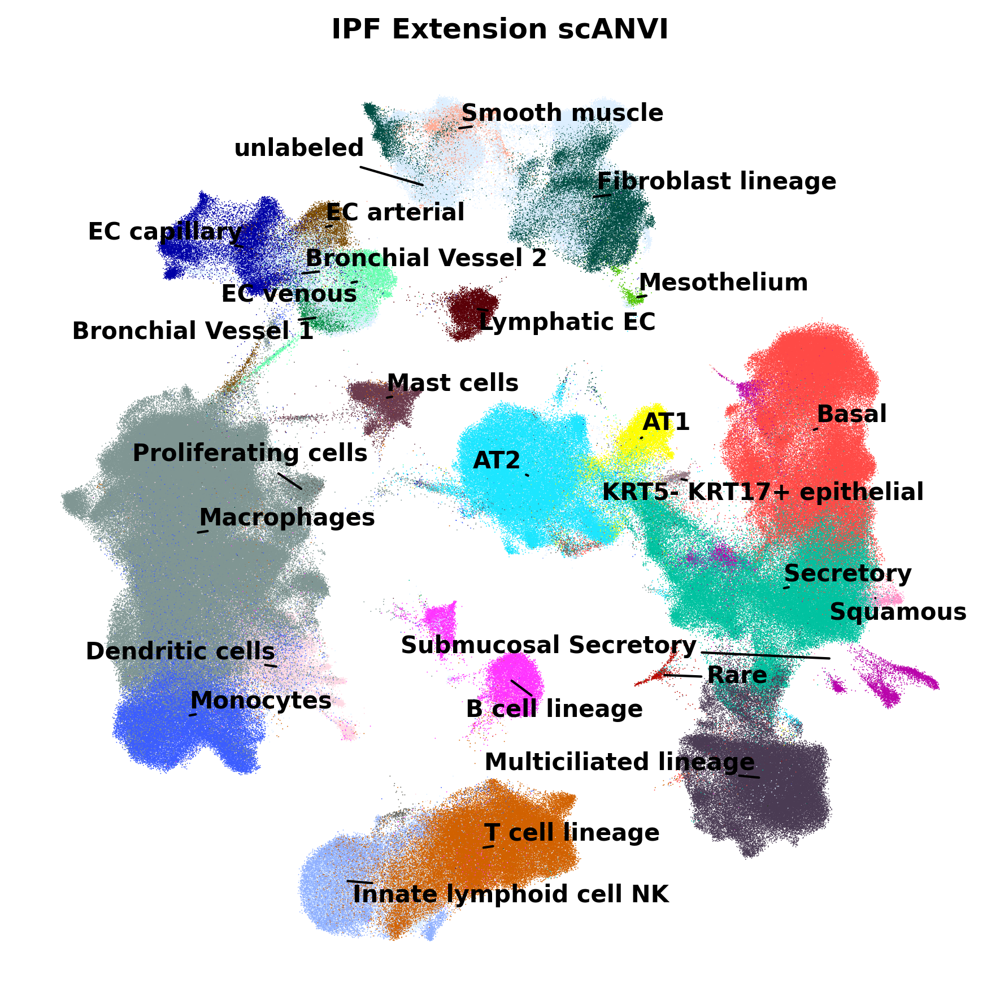

In [77]:
with plt.rc_context({"figure.figsize": (6,6), "figure.dpi": 300, "figure.frameon": False}):
    ax = sc.pl.umap(denovo_recalc_ipf_plot, color="scanvi_label", palette = colordict, size = 0.75, sort_order = False, show=False, legend_loc=None, frameon=False)
    gen_mpl_labels(
        denovo_recalc_ipf_plot,
        "scanvi_label",
        exclude=("None","unlabeled","Neutrophilic","Megakaryocytes","Proliferating cells","Erythroblast"),  # This was before we had the `nan` behaviour
        ax=ax,
        adjust_kwargs=dict(arrowprops=dict(arrowstyle='-', color='black')),
        text_kwargs=dict(fontsize=10, weight="semibold"),
    )
    ax.annotate('unlabeled', (0.42, 0.8), #arrow starts here
            xytext=(0.23, 0.83), xycoords='figure fraction',
                arrowprops=dict(arrowstyle='-', color='black'),
                fontsize=10, weight="semibold")
    ax.annotate('Proliferating cells', (0.3, 0.5), #arrow starts here
            xytext=(0.13, 0.53), xycoords='figure fraction',
                arrowprops=dict(arrowstyle='-', color='black'),
                fontsize=10, weight="semibold")

   
    fig = ax.get_figure()
    fig.tight_layout()
    plt.title("IPF Extension scANVI",fontweight="bold")
    plt.savefig("figures/IPF_extension_scANVI.png")
    #plt.show()
   

/opt/python/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:1227: FutureWarning: Categorical.replace is deprecated and will be removed in a future version. Use Series.replace directly instead.
  values = values.replace(values.categories.difference(groups), np.nan)


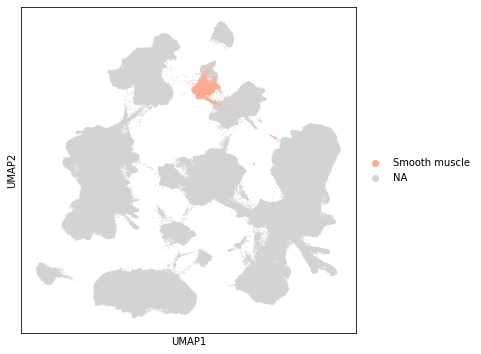

In [102]:
sc.pl.umap(denovo_recalc_ipf_plot, color=["scanvi_label"], palette = colordict, size = 3,groups="Smooth muscle"    )

# Nucleus Extension

In [4]:
# Import nucleus models
denovo_recalc_nucleus = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Nucleus/nucleus_denovo_recalc_milo.h5ad")
denovo_ref_nucleus = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Nucleus/nucleus_denovo_ref_milo.h5ad")
scarches_unlabeled_nucleus = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Nucleus/nucleus_scarches_unlabeled_milo.h5ad")
scarches_labeled_nucleus = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Data_Milo/Nucleus/nucleus_scarches_labeled_milo.h5ad")

In [5]:
# get original scanvi_labels for scarches_unlabeld back
scarches_unlabeled_nucleus.obs["scanvi_label_original"] = scarches_unlabeled_nucleus.obs["scanvi_label_original"].astype("string")
scarches_unlabeled_nucleus.obs.loc[scarches_unlabeled_nucleus.obs.origin=="reference","scanvi_label_original"] = scarches_unlabeled_nucleus.obs.loc[scarches_unlabeled_nucleus.obs.origin=="reference","scanvi_label"].astype(str)
scarches_unlabeled_nucleus.obs["scanvi_label_original"] = scarches_unlabeled_nucleus.obs["scanvi_label_original"].astype("category")

In [6]:
denovo_recalc_nucleus_plot = sc.pp.subsample(denovo_recalc_nucleus, fraction=1., copy=True)
denovo_ref_nucleus_plot = sc.pp.subsample(denovo_ref_nucleus, fraction=1., copy=True)
scarches_unlabeled_nucleus_plot = sc.pp.subsample(scarches_unlabeled_nucleus, fraction=1., copy=True)
scarches_labeled_nucleus_plot = sc.pp.subsample(scarches_labeled_nucleus, fraction=1., copy=True)

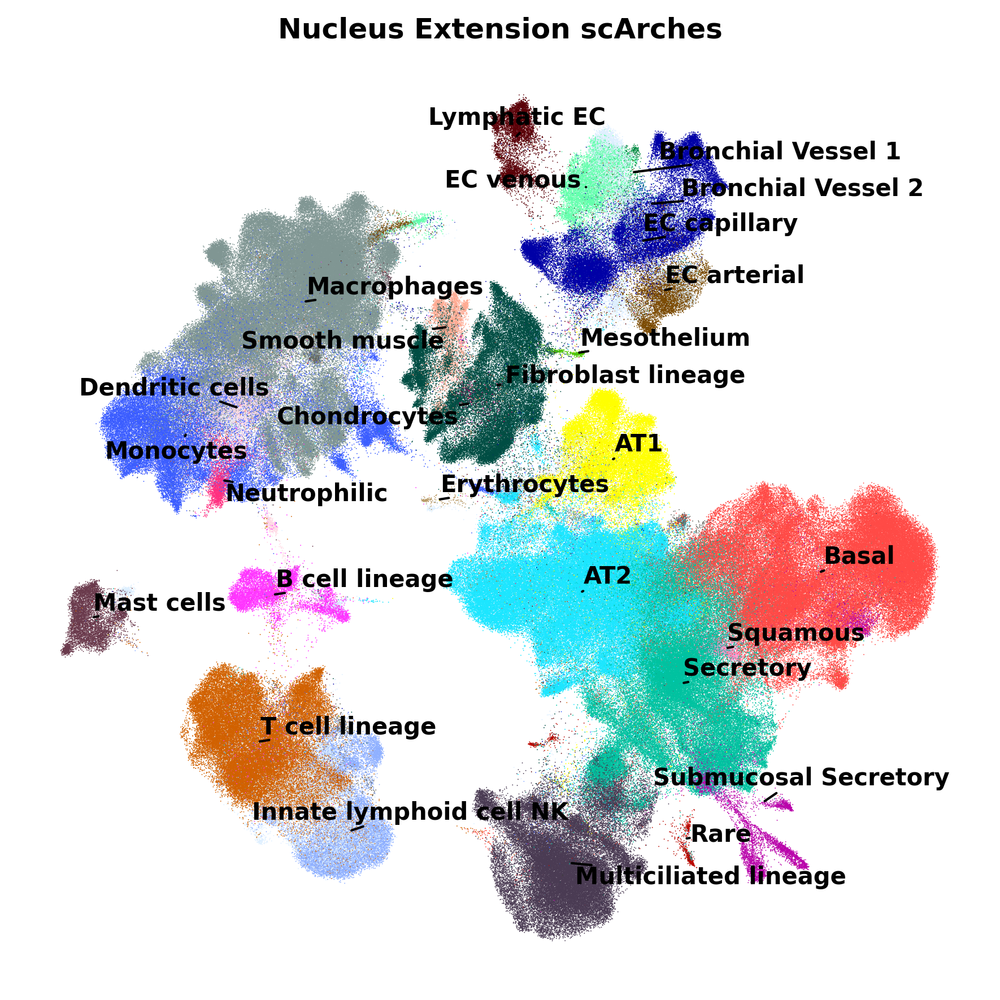

In [45]:
with plt.rc_context({"figure.figsize": (6,6), "figure.dpi": 300, "figure.frameon": False}):
    ax = sc.pl.umap(scarches_unlabeled_nucleus_plot, color="scanvi_label_original", palette = colordict, size = 0.75, sort_order = False, show=False, legend_loc=None, frameon=False)
    gen_mpl_labels(
        scarches_unlabeled_nucleus_plot,
        "scanvi_label_original",
        exclude=("None","Proliferating cells", "unlabeled","BASCs","KRT5- KRT17+ epithelial","Megakaryocytes"),  
        ax=ax,
        adjust_kwargs=dict(arrowprops=dict(arrowstyle='-', color='black')),
        text_kwargs=dict(fontsize=10, weight="semibold"),
    )

    fig = ax.get_figure()
    fig.tight_layout()
    plt.title("Nucleus Extension scArches",fontweight="bold")
    plt.savefig("figures/Nucleus_extension_scArches.png")
    #plt.show()
   

/opt/python/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:1227: FutureWarning: Categorical.replace is deprecated and will be removed in a future version. Use Series.replace directly instead.
  values = values.replace(values.categories.difference(groups), np.nan)


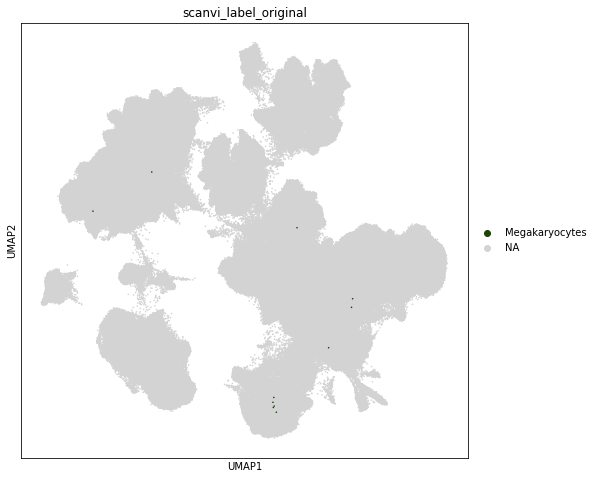

In [43]:
sc.pl.umap(scarches_unlabeled_nucleus_plot, color=["scanvi_label_original"], palette = colordict, size = 10,groups=["Megakaryocytes"])

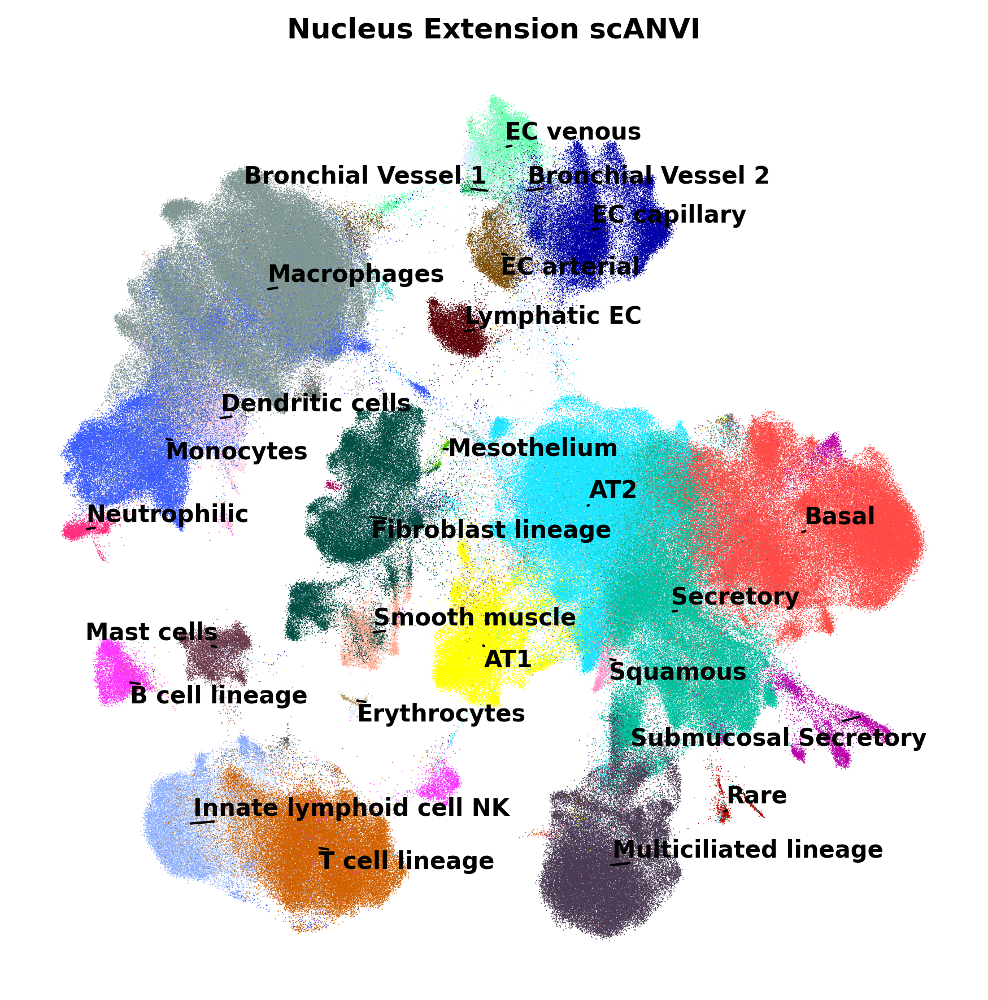

In [35]:
with plt.rc_context({"figure.figsize": (6,6), "figure.dpi": 300, "figure.frameon": False}):
    ax = sc.pl.umap(denovo_recalc_nucleus_plot, color="scanvi_label", palette = colordict, size = 0.75, sort_order = False, show=False, legend_loc=None, frameon=False)
    gen_mpl_labels(
        denovo_recalc_nucleus_plot,
        "scanvi_label",
        exclude=("None","Proliferating cells","unlabeled","Chondrocytes","BASCs","KRT5- KRT17+ epithelial","Megakaryocytes","Submucosal Secretory"),  
        ax=ax,
        adjust_kwargs=dict(arrowprops=dict(arrowstyle='-', color='black')),
        text_kwargs=dict(fontsize=10, weight="semibold"),
    )
    
    ax.annotate('Submucosal Secretory', (0.85, 0.28), #arrow starts here
            xytext=(0.62, 0.25), xycoords='figure fraction',
                arrowprops=dict(arrowstyle='-', color='black'),
                fontsize=10, weight="semibold")

    fig = ax.get_figure()
    fig.tight_layout()
    plt.title("Nucleus Extension scANVI",fontweight="bold")
    plt.savefig("figures/Nucleus_extension_scANVI.png")
    #plt.show()
   

/opt/python/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:1227: FutureWarning: Categorical.replace is deprecated and will be removed in a future version. Use Series.replace directly instead.
  values = values.replace(values.categories.difference(groups), np.nan)


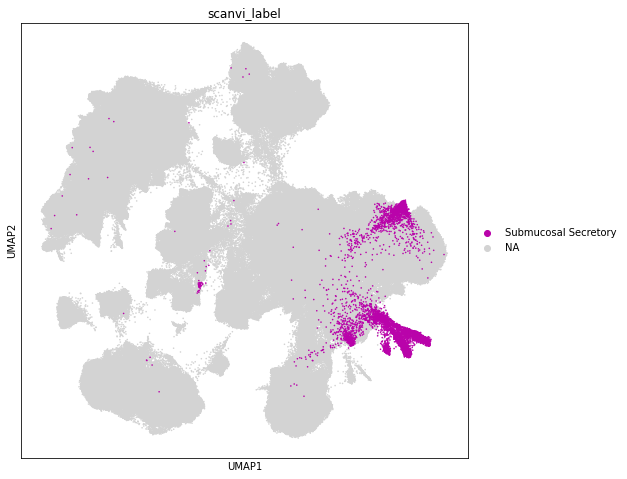

In [27]:
sc.pl.umap(denovo_recalc_nucleus_plot, color=["scanvi_label"], palette = colordict, size = 10,groups="Submucosal Secretory"    )